# Customer Segmentation Using RFM Analysis 

# Penjelasan Dataset

| No. | Column Name | Description |
|---:|---|---|
| 1 | `ORDERNUMBER` | Nomor unik untuk mengidentifikasi pesanan pelanggan. |
| 2 | `QUANTITYORDERED` | Jumlah unit produk yang dipesan. |
| 3 | `PRICEEACH` | Harga per unit produk dalam pesanan. |
| 4 | `ORDERLINENUMBER` | Nomor urut item produk di dalam suatu pesanan. |
| 5 | `SALES` | Total nilai penjualan untuk item pada baris transaksi tersebut. |
| 6 | `ORDERDATE` | Tanggal pesanan dibuat. |
| 7 | `DAYS_SINCE_LASTORDER` | Jumlah hari sejak pesanan terakhir berdasarkan informasi yang tersedia dalam dataset. |
| 8 | `STATUS` | Status pesanan, seperti Shipped, Cancelled, atau status lainnya. |
| 9 | `PRODUCTLINE` | Kategori atau lini produk yang dipesan. |
| 10 | `MSRP` | Manufacturer's Suggested Retail Price, yaitu harga eceran yang disarankan produsen. |
| 11 | `PRODUCTCODE` | Kode untuk mengidentifikasi produk. |
| 12 | `CUSTOMERNAME` | Nama perusahaan yang melakukan pemesanan. |
| 13 | `PHONE` | Nomor telepon kontak pelanggan. |
| 14 | `ADDRESSLINE1` | Alamat utama pelanggan. |
| 15 | `CITY` | Kota tempat pelanggan berada. |
| 16 | `POSTALCODE` | Kode pos alamat pelanggan. |
| 17 | `COUNTRY` | Negara tempat pelanggan berada. |
| 18 | `CONTACTLASTNAME` | Nama belakang orang yang menjadi kontak pelanggan. |
| 19 | `CONTACTFIRSTNAME` | Nama depan orang yang menjadi kontak pelanggan. |
| 20 | `DEALSIZE` | Kategori ukuran transaksi, seperti Small, Medium, atau Large. |


# Import Data

# Library Yang Digunakan

In [55]:
import pandas as pd # Digunakan untuk mengimpor, mengelola, membersihkan, dan menganalisis data dalam format tabel dua dimensi (tabular data).
import numpy as np # Digunakan untuk komputasi numerik berskala besar, termasuk membantu perhitungan fungsi massa probabilitas (Probability Mass Function / PMF) serta operasi matematika dan analisis statistik.
import matplotlib.pyplot as plt # Digunakan sebagai pustaka dasar untuk merancang dan membuat visualisasi data dua dimensi, seperti grafik garis, diagram batang, dan tebaran titik.
import seaborn as sns # Digunakan untuk membuat visualisasi data bertema statistik yang lebih estetis, modern, dan informatif dengan sintaks yang lebih ringkas.
from scipy import stats # # Digunakan untuk melakukan berbagai komputasi, pengujian, dan analisis statistik tingkat lanjut, seperti uji hipotesis, perhitungan nilai probabilitas (p-value), serta pengelolaan berbagai jenis distribusi statistik.

# Load Dataset

In [56]:
df=pd.read_csv(r"C:\Users\HP\OneDrive\Desktop\Mini Project\Automobile Sales data.csv") # Data disimpan di folder 'Mini Project' dengan nama 'Automobile Sales data.csv'

# Data Exploration

# Menampilkan Data

In [57]:
df.head() # menampilkan 5 baris teratas atau pertama dari dataset

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


df.info() memberikan ringkasan struktur DataFrame, termasuk jumlah baris, kolom, tipe data, nilai non-null, dan penggunaan memori, membantu memahami data sebelum analisis.

In [58]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   str    
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   str    
 8   PRODUCTLINE           2747 non-null   str    
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   str    
 11  CUSTOMERNAME          2747 non-null   str    
 12  PHONE                 2747 non-null   str    
 13  ADDRESSLINE1          2747 non-null   str    
 14  CITY                  2747 non-null   str    
 15  POSTALCODE            2747 non-n

Hasil output:
- Dataset berisi 2747 baris dan 20 kolom
- Tidak terdapat missing values pada data
- Kolom ORDERDATE perlu diubah ke datetime
- Kolom ORDERNUMBER merupakan ID yang perlu diubah menjadi str

# Menampilkan ringkasan statistik

In [59]:
df.describe()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,DAYS_SINCE_LASTORDER,MSRP
count,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000
mean,10259.761558,35.103021,101.098952,6.491081,3553.047583,1757.085912,100.691664
std,91.877521,9.762135,42.042549,4.230544,1838.953901,819.280576,40.114802
min,10100.000000,6.000000,26.880000,1.000000,482.130000,42.000000,33.000000
25%,10181.000000,27.000000,68.745000,3.000000,2204.350000,1077.000000,68.000000
50%,10264.000000,35.000000,95.550000,6.000000,3184.800000,1761.000000,99.000000
75%,10334.500000,43.000000,127.100000,9.000000,4503.095000,2436.500000,124.000000
max,10425.000000,97.000000,252.870000,18.000000,14082.800000,3562.000000,214.000000


Hasil output:
- DAYS_SINCE_LASTORDER memiliki nilai yang sangat besar 42–3.562 hari
Rata-ratanya 1.757 hari, atau sekitar 4,8 tahun. Ini perlu diperiksa karena periode transaksi pada dataset hanya sekitar tahun 2018–2020.
- SALES maksimum jauh lebih tinggi daripada median
14.082,80 vs. 3.184,80
Nilai maksimum sekitar 4,4 kali median. Ini menunjukkan transaksi bernilai tinggi yang perlu diperiksa, tetapi belum tentu merupakan kesalahan atau outlier yang harus dihapus.

# Distribusi Data

- Dilakukan pemeriksaan distribusi data untuk mengetahui pola sebaran nilai pada setiap variabel.
- Pemeriksaan ini bertujuan untuk melihat apakah data berdistribusi normal atau tidak, sehingga dapat ditentukan metode analisis yang sesuai pada tahap selanjutnya.
- Pemeriksaan persebaran data menggunakan Histogram dan Q-Q Plot

# Visualisasi Distribusi Kolom Numerik

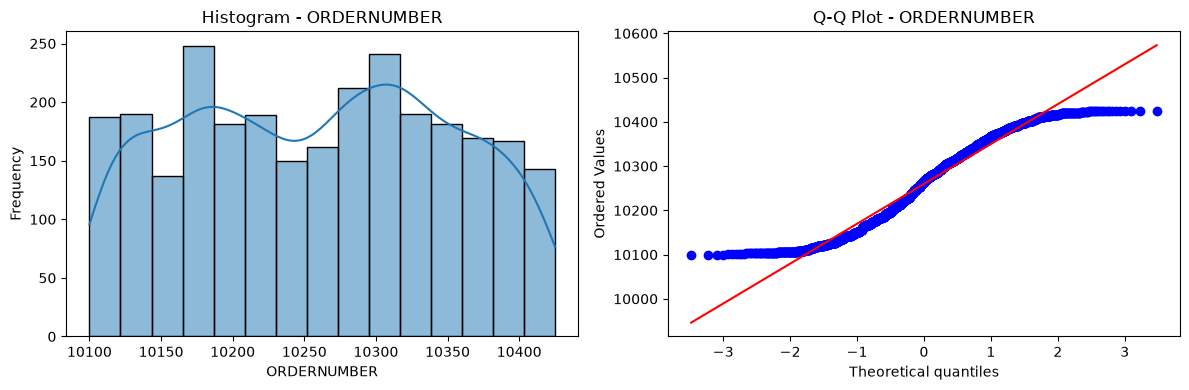

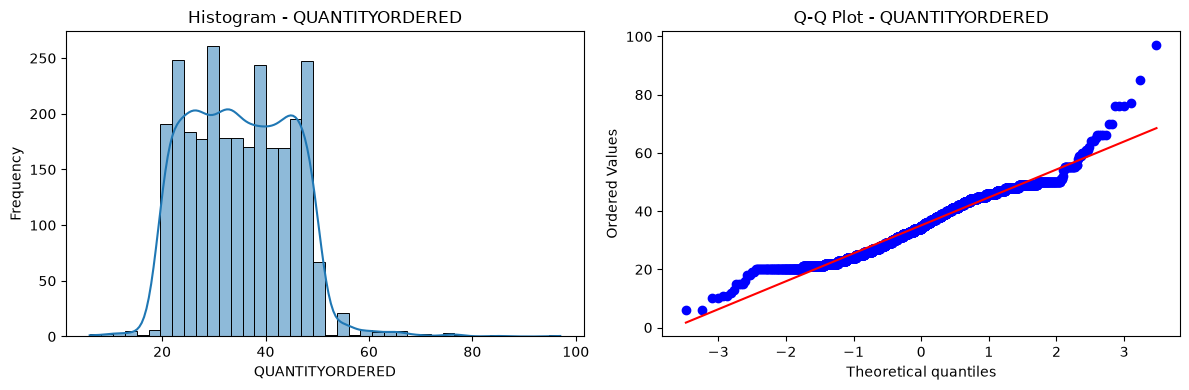

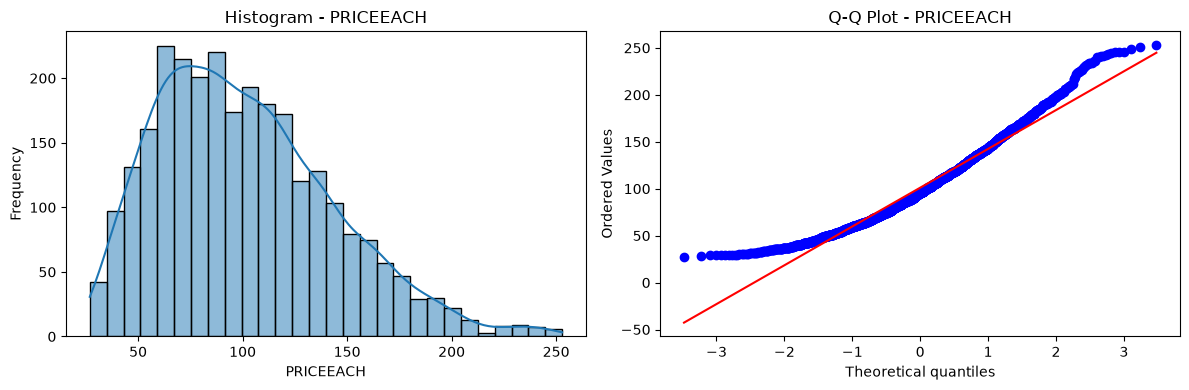

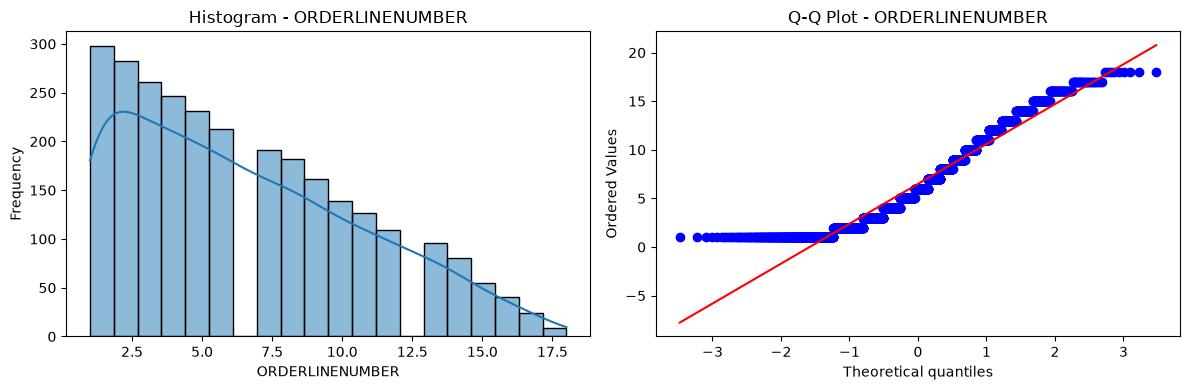

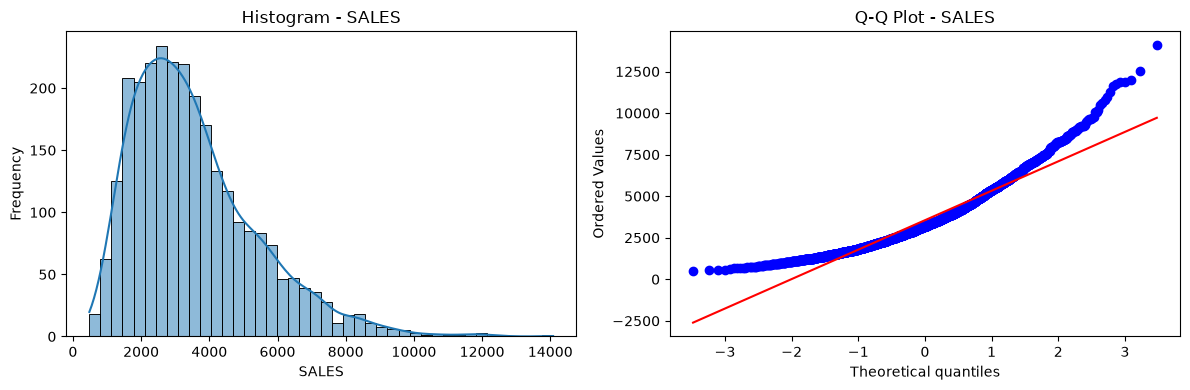

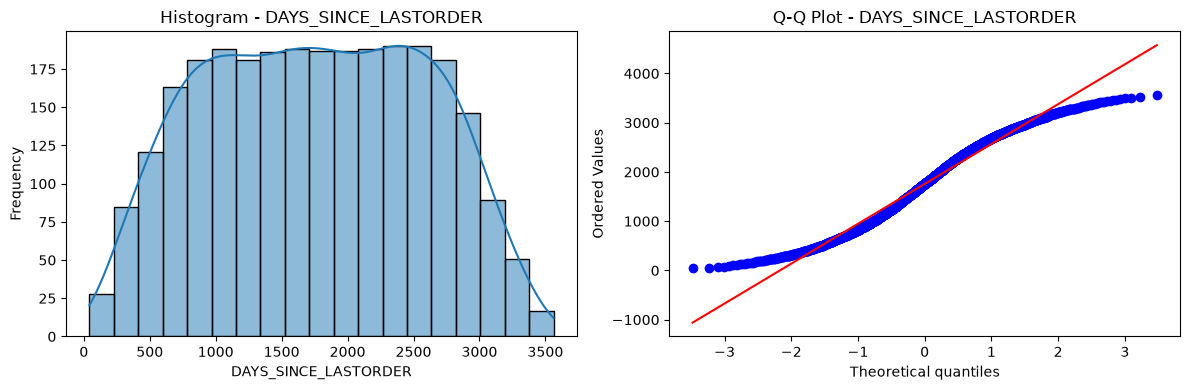

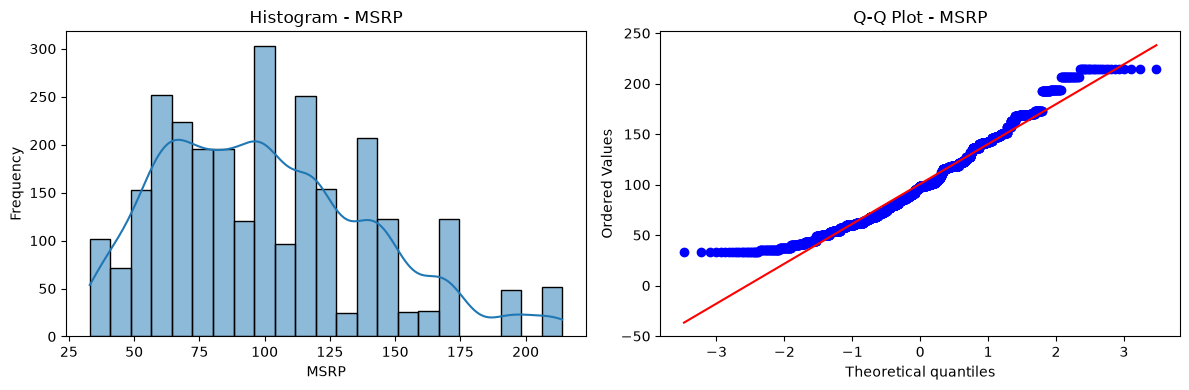

In [60]:
# Pilih seluruh kolom numerik
numeric_cols = df.select_dtypes(include="number").columns.tolist()

# Buat histogram dan Q-Q plot untuk setiap kolom
for col in numeric_cols:
    data = df[col].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Histogram
    sns.histplot(data, kde=True, ax=axes[0])
    axes[0].set_title(f"Histogram - {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frequency")

    # Q-Q plot
    stats.probplot(data, dist="norm", plot=axes[1])
    axes[1].set_title(f"Q-Q Plot - {col}")

    plt.tight_layout()
    plt.show()


Hasil Output:
- QUANTITYORDERED: Sebagian besar pesanan berisi sekitar 20–50 unit, sementara beberapa mencapai sekitar 80–97 unit. Q-Q plot menyimpang pada bagian ujung atas. Ini menunjukkan adanya pesanan dengan jumlah produk relatif besar.
- PRICEEACH (Distribusi miring ke kanan): Harga banyak terkonsentrasi di sekitar 50–120, kemudian frekuensinya menurun pada harga yang lebih tinggi. Q-Q plot melengkung dari garis merah. Pola ini bisa terjadi karena produk memiliki rentang harga berbeda.
- SALES: Histogram miring ke kanan. Sebagian besar nilai penjualan berada di rentang yang lebih rendah, tetapi ada sejumlah transaksi dengan nilai sangat tinggi. Q-Q plot juga menyimpang kuat pada bagian atas. Ini menunjukkan distribusi penjualan yang tidak simetris. Periksa transaksi dengan nilai tertinggi untuk memastikan tidak ada kesalahan pencatatan. Transaksi besar tetap bisa valid, terutama jika jumlah produk atau harga per unitnya tinggi.

# Visualisasi Distribusi Kolom Kategorikal

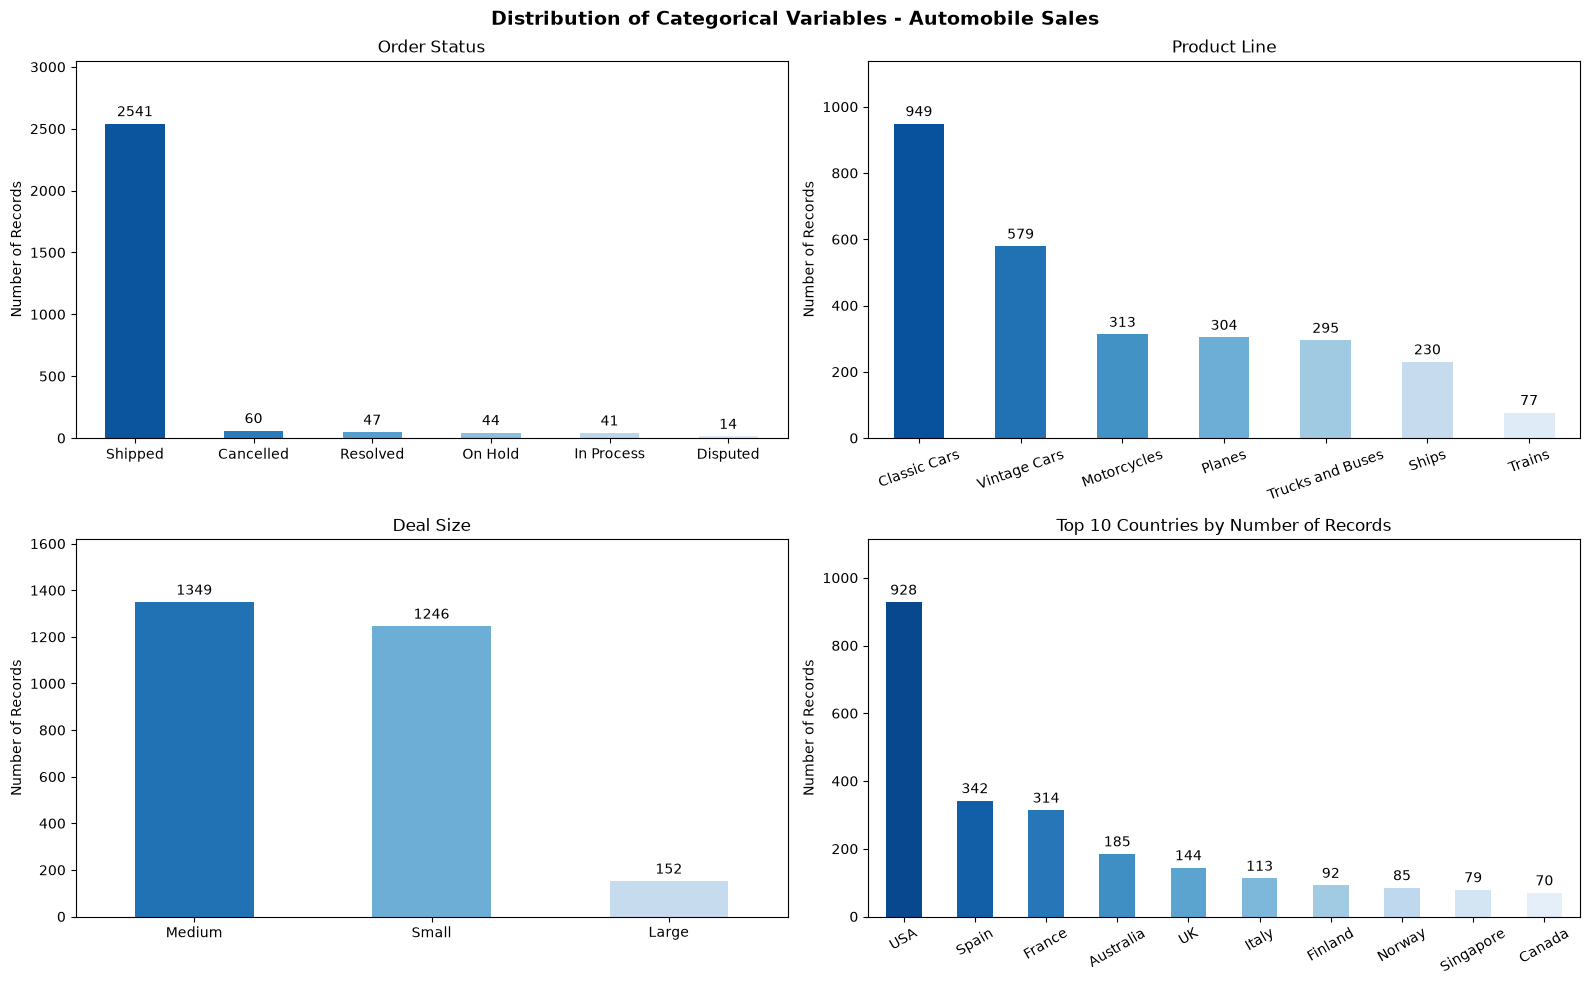

In [61]:
# Membuat layout 2 baris x 2 kolom
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

fig.suptitle(
    'Distribution of Categorical Variables - Automobile Sales',
    fontsize=14,
    fontweight='bold'
)

# 1. Status
counts_status = df['STATUS'].value_counts()

counts_status.plot(
    kind='bar',
    ax=axes[0, 0],
    color=sns.color_palette('Blues_r', len(counts_status))
)

axes[0, 0].bar_label(axes[0, 0].containers[0], padding=3)
axes[0, 0].set_title('Order Status')
axes[0, 0].tick_params(axis='x', rotation=0)
axes[0, 0].set_ylim(0, counts_status.max() * 1.20)
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Number of Records')

# 2. Product Line
counts_productline = df['PRODUCTLINE'].value_counts()

counts_productline.plot(
    kind='bar',
    ax=axes[0, 1],
    color=sns.color_palette('Blues_r', len(counts_productline))
)

axes[0, 1].bar_label(axes[0, 1].containers[0], padding=3)
axes[0, 1].set_title('Product Line')
axes[0, 1].tick_params(axis='x', rotation=20)
axes[0, 1].set_ylim(0, counts_productline.max() * 1.20)
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Number of Records')

# 3. Deal Size
counts_dealsize = df['DEALSIZE'].value_counts()

counts_dealsize.plot(
    kind='bar',
    ax=axes[1, 0],
    color=sns.color_palette('Blues_r', len(counts_dealsize))
)

axes[1, 0].bar_label(axes[1, 0].containers[0], padding=3)
axes[1, 0].set_title('Deal Size')
axes[1, 0].tick_params(axis='x', rotation=0)
axes[1, 0].set_ylim(0, counts_dealsize.max() * 1.20)
axes[1, 0].set_xlabel('')
axes[1, 0].set_ylabel('Number of Records')

# 4. Country (10 negara dengan transaksi terbanyak)
counts_country = df['COUNTRY'].value_counts().head(10)

counts_country.plot(
    kind='bar',
    ax=axes[1, 1],
    color=sns.color_palette('Blues_r', len(counts_country))
)

axes[1, 1].bar_label(axes[1, 1].containers[0], padding=3)
axes[1, 1].set_title('Top 10 Countries by Number of Records')
axes[1, 1].tick_params(axis='x', rotation=30)
axes[1, 1].set_ylim(0, counts_country.max() * 1.20)
axes[1, 1].set_xlabel('')
axes[1, 1].set_ylabel('Number of Records')

plt.tight_layout()
plt.show()


# Memeriksa Data Kosong

In [62]:
pd.isnull(df).sum()

ORDERNUMBER             0
QUANTITYORDERED         0
PRICEEACH               0
ORDERLINENUMBER         0
SALES                   0
ORDERDATE               0
DAYS_SINCE_LASTORDER    0
STATUS                  0
PRODUCTLINE             0
MSRP                    0
PRODUCTCODE             0
CUSTOMERNAME            0
PHONE                   0
ADDRESSLINE1            0
CITY                    0
POSTALCODE              0
COUNTRY                 0
CONTACTLASTNAME         0
CONTACTFIRSTNAME        0
DEALSIZE                0
dtype: int64

Hasil Output: Tidak ditemukan missing values pada dataset

# Memeriksa Data Duplikasi

In [63]:
df.duplicated().sum()

np.int64(0)

Hasil Output: Tidak terdapat data duplikasi

# Memeriksa konsistensi data

In [64]:
# Mengatur agar isi kolom (terutama list unique values) tidak terpotong saat ditampilkan
pd.set_option('display.max_colwidth', None)

# Membuat list kosong untuk menampung informasi setiap kolom
list_info = []

# Melakukan iterasi pada setiap kolom di dataframe
for col in df.columns:
    list_info.append([
        col,                                # Nama kolom
        df[col].dtype,                 # Tipe data kolom
        df[col].nunique(),             # Jumlah nilai unik pada kolom
        list(df[col].unique())         # Daftar seluruh nilai unik pada kolom
    ])

# Mengubah list menjadi DataFrame agar lebih mudah dibaca
df_info = pd.DataFrame(
    columns=['column', 'dtype', 'n_unique', 'unique_values'],
    data=list_info
)

# Menampilkan ringkasan informasi kolom
display(df_info)

,column,dtype,n_unique,unique_values
0,ORDERNUMBER,int64,298,"[10107, 10121, 10134, 10145, 10168, 10180, 10188, 10211, 10223, 10237, 10251, 10263, 10275, 10285, 10299, 10309, 10318, 10329, 10341, 10361, 10375, 10388, 10403, 10417, 10103, 10112, 10126, 10140, 10150, 10163, 10174, 10183, 10194, 10206, 10215, 10228, 10245, 10258, 10270, 10280, 10291, 10304, 10312, 10322, 10347, 10357, 10369, 10391, 10411, 10424, 10120, 10210, 10236, 10298, 10308, 10339, 10374, 10402, 10362, 10105, 10119, 10129, 10143, 10155, 10167, 10178, 10186, 10197, 10222, 10248, 10261, 10273, 10283, 10295, 10307, 10316, 10325, 10337, 10350, 10359, 10373, 10395, 10400, 10414, 10114, 10164, 10175, 10207, 10217, 10229, 10259, 10281, 10305, 10313, 10334, 10370, 10425, 10108, 10122, 10135, ...]"
1,QUANTITYORDERED,int64,58,"[30, 34, 41, 45, 36, 29, 48, 37, 23, 28, 46, 42, 20, 21, 24, 66, 26, 38, 47, 35, 32, 40, 50, 39, 27, 22, 44, 31, 33, 49, 43, 56, 25, 64, 19, 12, 55, 10, 54, 97, 61, 51, 59, 76, 6, 15, 60, 65, 58, 16, 70, 13, 18, 52, 11, 62, 85, 77]"
2,PRICEEACH,float64,1843,"[95.7, 81.35, 94.74, 83.26, 96.66, 86.13, 114.84, 107.18, 101.44, 113.88, 108.14, 92.83, 112.93, 104.67, 188.73, 72.55, 34.91, 76.36, 207.87, 248.59, 192.87, 199.3, 244.3, 231.44, 235.73, 233.59, 173.58, 222.87, 180.01, 240.02, 216.44, 242.16, 150.01, 131.49, 177.87, 110.12, 100.69, 99.91, 96.34, 122.51, 140.35, 135.59, 111.8, 130.83, 115.37, 129.64, 132.02, 137.97, 118.94, 123.7, 158.8, 68.92, 51.15, 44.51, 224.65, 201.41, 226.58, 156.86, 209.15, 216.9, 193.66, 180.1, 199.47, 164.61, 203.34, 191.72, 230.46, 228.52, 207.22, 225.7, 76.67, 166.55, 174.29, 86.77, 144.16, 108.8, 133.28, 114.24, 141.44, 134.64, 145.52, 148.24, 118.32, 122.4, 125.12, 116.96, 119.68, 142.8, 64.93, 48.05, 75.47, 54.68, 103.75, 105.33, 150.96, 128.53, 138.88, 152.17, 122.62, 159.56, ...]"
3,ORDERLINENUMBER,int64,18,"[2, 5, 6, 1, 9, 14, 7, 13, 12, 4, 11, 8, 3, 10, 15, 17, 16, 18]"
4,SALES,float64,2690,"[2871.0, 2765.9, 3884.34, 3746.7, 3479.76, 2497.77, 5512.32, 4708.44, 3965.66, 2333.12, 3188.64, 3676.76, 4177.35, 4099.68, 2597.39, 4394.38, 4358.04, 4396.14, 7737.93, 1451.0, 733.11, 3207.12, 2434.56, 7516.08, 5404.62, 7209.11, 7329.06, 7374.1, 10993.5, 4860.24, 8014.82, 5372.57, 7290.36, 9064.89, 6075.3, 6463.23, 6120.34, 7680.64, 4905.39, 7136.19, 10172.7, 11623.7, 6000.4, 3944.7, 5691.84, 4514.92, 2416.56, 4140.23, 12001.0, 3896.49, 2793.86, 3307.77, 5192.95, 3660.93, 4695.6, 3660.92, 3009.09, 5422.39, 2852.08, 5756.52, 4472.0, 2904.44, 6484.59, 3757.26, 4043.96, 5566.5, 3176.0, 2756.8, 1329.9, 5288.01, 2225.5, 5833.8, 5887.35, 6065.55, 9264.86, 7023.98, 5176.38, 4183.0, 8892.9, 8714.7, 6123.4, 9774.03, 7023.9, 7078.23, 8336.94, 6901.92, 5438.07, 6683.34, 4570.4, 7667.14, 5868.2, 2990.13, 3664.1, 3834.38, 1822.17, 11886.6, 9218.16, 7208.0, 5004.8, 4398.24, ...]"
5,ORDERDATE,str,246,"[24/02/2018, 07/05/2018, 01/07/2018, 25/08/2018, 28/10/2018, 11/11/2018, 18/11/2018, 15/01/2019, 20/02/2019, 05/04/2019, 18/05/2019, 28/06/2019, 23/07/2019, 27/08/2019, 30/09/2019, 15/10/2019, 02/11/2019, 15/11/2019, 24/11/2019, 17/12/2019, 03/02/2020, 03/03/2020, 08/04/2020, 13/05/2020, 29/01/2018, 24/03/2018, 28/05/2018, 24/07/2018, 19/09/2018, 20/10/2018, 06/11/2018, 13/11/2018, 25/11/2018, 05/12/2018, 29/01/2019, 10/03/2019, 04/05/2019, 15/06/2019, 19/07/2019, 17/08/2019, 08/09/2019, 11/10/2019, 21/10/2019, 04/11/2019, 29/11/2019, 10/12/2019, 20/01/2020, 09/03/2020, 01/05/2020, 31/05/2020, 29/04/2018, 12/01/2019, 03/04/2019, 27/09/2019, 23/11/2019, 02/02/2020, 07/04/2020, 05/01/2020, 11/02/2018, 28/04/2018, 12/06/2018, 10/08/2018, 06/10/2018, 23/10/2018, 08/11/2018, 14/11/2018, 26/11/2018, 19/02/2019, 07/05/2019, 17/06/2019, 21/07/2019, 20/08/2019, 10/09/2019, 14/10/2019, 01/11/2019, 05/11/2019, 21/11/2019, 02/12/2019, 15/12/2019, 31/01/2020, 17/03/2020, 01/04/2020, 06/05/2020, 01/04/2018, 21/10/2018, 09/12/2018, 04/02/2019, 11/03/2019, 19/08/2019, 13/10/2019, 22/10/2019, 19/11/2019, 03/03/2018, 08/05/2018, 02/07/2018, 05/09/2018, 0

Hasil Output: Tidak terdapat inkonsistensi data.

# DATA CLEANING

Membuat data frame baru salinan dari df agar ketika digunakan untuk analisis tidak merusak data asli

In [65]:
df_cleaned = df.copy()

# Mengubah Kolom ORDERDATE menjadi datetime

In [66]:
df_cleaned['ORDERDATE'] = pd.to_datetime(
    df_cleaned['ORDERDATE'],
    dayfirst=True
)

# Mengubah kolom ORDERNUMBER menjadi str

In [67]:
df_cleaned['ORDERNUMBER'] = df_cleaned['ORDERNUMBER'].astype(str)

# Sebelum Data Cleaning

In [68]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   str    
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   str    
 8   PRODUCTLINE           2747 non-null   str    
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   str    
 11  CUSTOMERNAME          2747 non-null   str    
 12  PHONE                 2747 non-null   str    
 13  ADDRESSLINE1          2747 non-null   str    
 14  CITY                  2747 non-null   str    
 15  POSTALCODE            2747 non-n

# Setelah Data Cleaning

In [69]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   ORDERNUMBER           2747 non-null   str           
 1   QUANTITYORDERED       2747 non-null   int64         
 2   PRICEEACH             2747 non-null   float64       
 3   ORDERLINENUMBER       2747 non-null   int64         
 4   SALES                 2747 non-null   float64       
 5   ORDERDATE             2747 non-null   datetime64[us]
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64         
 7   STATUS                2747 non-null   str           
 8   PRODUCTLINE           2747 non-null   str           
 9   MSRP                  2747 non-null   int64         
 10  PRODUCTCODE           2747 non-null   str           
 11  CUSTOMERNAME          2747 non-null   str           
 12  PHONE                 2747 non-null   str           
 13  ADDRESSLINE1          2747 no

# Deteksi outlier menggunakan Metode IQR

In [70]:
# Pilih semua kolom dengan tipe data integer
int_cols = df_cleaned.select_dtypes(include=['int64', 'int32', 'float64']).columns

# Hitung Q1, Q3, dan IQR
q1 = df_cleaned[int_cols].quantile(0.25)
q3 = df_cleaned[int_cols].quantile(0.75)
iqr = q3 - q1

# Hitung batas bawah dan batas atas
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Buat mask untuk mendeteksi outlier
mask = (df_cleaned[int_cols] < lower) | (df_cleaned[int_cols] > upper)

# Ambil baris yang memiliki minimal satu outlier
outliers = df_cleaned[mask.any(axis=1)]

# Tampilkan kolom integer yang mengandung outlier
outliers[int_cols]

,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,DAYS_SINCE_LASTORDER,MSRP
24,26,207.87,11,5404.62,878,214
25,29,248.59,1,7209.11,825,214
26,38,192.87,11,7329.06,761,214
27,37,199.30,11,7374.10,705,214
28,45,244.30,8,10993.50,649,214
...,...,...,...,...,...,...
2358,45,199.49,3,8977.05,2434,58
2432,46,218.84,2,10066.60,2522,91
2511,85,88.75,10,7543.75,2570,99
2559,46,207.80,2,9558.80,2753,101


In [71]:
for col in int_cols:
    q1 = df_cleaned[col].quantile(0.25)
    q3 = df_cleaned[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = (
        (df_cleaned[col] < lower) |
        (df_cleaned[col] > upper)
    ).sum()

    if count > 0:
        print(f"{col}: {count} outlier")


QUANTITYORDERED: 8 outlier
PRICEEACH: 33 outlier
SALES: 79 outlier
MSRP: 26 outlier


## Penanganan Outlier

Outlier dipertahankan karena nilai ekstrem masih berpotensi mencerminkan kondisi transaksi yang valid dan dapat memberikan informasi penting dalam analisis penjualan.

# Customer Segmentation Using RFM Analysis

RFM adalah singkatan dari Recency, Frequency, Monetary, yang merupakan metode untuk mengevaluasi nilai pelanggan, dan mengelompokkan pelanggan berdasarkan nilai segmentasi. Menurut Anitha & Patil (2022), RFM membagi nilai pelanggan ke dalam tiga metrik utama:
- Recency: Seberapa lama jeda waktu sejak transaksi terakhir pelanggan. Semakin kecil nilainya (baru saja bertransaksi), semakin baik prospeknya.
- Frequency: Seberapa sering pelanggan tersebut melakukan transaksi dengan bisnis kita hingga saat ini. Semakin tinggi nilainya, semakin baik.
- Monetary: Seberapa besar total pengeluaran uang yang dihasilkan oleh pelanggan tersebut untuk meningkatkan revenue perusahaan. Sama seperti frequency, semakin tinggi nilainya maka semakin baik.

# Kolom yang Dibutuhkan

In [72]:
temp = [
    'CUSTOMERNAME',
    'ORDERNUMBER',
    'ORDERDATE',
    'SALES'
]

RFM_data = df_cleaned[temp].copy()

print("Jumlah baris dan kolom:",RFM_data.shape)
RFM_data.head()

Jumlah baris dan kolom: (2747, 4)


,CUSTOMERNAME,ORDERNUMBER,ORDERDATE,SALES
0,Land of Toys Inc.,10107,2018-02-24,2871.00
1,Reims Collectables,10121,2018-05-07,2765.90
2,Lyon Souveniers,10134,2018-07-01,3884.34
3,Toys4GrownUps.com,10145,2018-08-25,3746.70
4,Technics Stores Inc.,10168,2018-10-28,3479.76


# Persiapan Sebelum Membuat Tabel RFM

## Menghitung Rentang Waktu Pada Dataset

In [73]:
tanggal_awal = df_cleaned['ORDERDATE'].min()
tanggal_akhir = df_cleaned['ORDERDATE'].max()

print("Tanggal paling awal:", tanggal_awal.strftime('%d %B %Y'))
print("Tanggal paling akhir:", tanggal_akhir.strftime('%d %B %Y'))
print("Rentang hari:", (tanggal_akhir - tanggal_awal).days)

Tanggal paling awal: 06 January 2018
Tanggal paling akhir: 31 May 2020
Rentang hari: 876


## Menghitung Tanggal Referensi

In [74]:
reference_date = (
    df_cleaned['ORDERDATE'].max()
    + pd.Timedelta(days=1)
)

print("Tanggal referensi:", reference_date)

Tanggal referensi: 2020-06-01 00:00:00


Hasil Output: Berdasarkan hasil pemeriksaan, tanggal transaksi terakhir dalam dataset adalah 31 Mei 2020. Oleh karena itu, saya menggunakan 1 Juni 2020 sebagai tanggal referensi (reference_date) untuk menghitung Recency. Dengan pendekatan ini, transaksi terakhir pada 31 Mei 2020 memiliki nilai Recency sebesar 1 hari, bukan 0 hari.

# Membuat Tabel RFM

In [75]:
# RFM Table
RFM_table = RFM_data.groupby('CUSTOMERNAME').agg({
    'ORDERDATE': lambda x: (reference_date - x.max()).days,  # Recency
    'ORDERNUMBER': 'nunique',                     # Frequency
    'SALES': 'sum'                                # Monetary
})

# Ganti nama kolom
RFM_table.rename(columns={
    'ORDERDATE': 'recency',
    'ORDERNUMBER': 'frequency',
    'SALES': 'monetary_value'
}, inplace=True)

RFM_table['recency'] = RFM_table['recency'].astype(int)

RFM_table.head()

,recency,frequency,monetary_value
CUSTOMERNAME,,,
"AV Stores, Co.",197,3,157807.81
Alpha Cognac,65,3,70488.44
Amica Models & Co.,266,2,94117.26
"Anna's Decorations, Ltd",84,4,153996.13
Atelier graphique,189,3,24179.96


In [76]:
RFM_table = RFM_table.reset_index() # Menghapus index CUSTOMERNAME agar dapat dipakai untuk membuat RFM Score

# Menghitung Batas Kuartil

In [77]:
quantiles = RFM_table.quantile(
    q=[0.25, 0.5, 0.75],
    numeric_only=True
)
quantiles

,recency,frequency,monetary_value
0.25,76.0,2.0,70488.44
0.50,185.0,3.0,87489.23
0.75,231.0,3.0,120562.74


# Membuat RFM Score

In [78]:
# Recency: semakin kecil semakin baik
RFM_table['R_Quartile'] = pd.qcut(
    RFM_table['recency'].rank(method='first', ascending=True),
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: semakin besar semakin baik
RFM_table['F_Quartile'] = pd.qcut(
    RFM_table['frequency'].rank(method='first'),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: semakin besar semakin baik
RFM_table['M_Quartile'] = pd.qcut(
    RFM_table['monetary_value'].rank(method='first'),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Gabungkan skor
RFM_table['RFM_Score'] = (
    RFM_table['R_Quartile'].astype(str)
    + RFM_table['F_Quartile'].astype(str)
    + RFM_table['M_Quartile'].astype(str)
)

RFM_table.head()

,CUSTOMERNAME,recency,frequency,monetary_value,R_Quartile,F_Quartile,M_Quartile,RFM_Score
0,"AV Stores, Co.",197,3,157807.81,2,2,4,224
1,Alpha Cognac,65,3,70488.44,4,2,1,421
2,Amica Models & Co.,266,2,94117.26,1,1,3,113
3,"Anna's Decorations, Ltd",84,4,153996.13,3,4,4,344
4,Atelier graphique,189,3,24179.96,2,2,1,221


# Membuat Segment Pelanggan Berdasarkan RFM Score

In [81]:

def assign_segment(row):
    r = row['R_Quartile']
    f = row['F_Quartile']
    m = row['M_Quartile']

    if r >= 3 and f >= 3 and m >= 3:
        return 'Champions'
    elif r >= 2 and f >= 3:
        return 'Loyal Customers'
    elif r >= 3 and f >= 2:
        return 'Potential Loyalist'
    elif r == 4 and f == 1:
        return 'New Customers'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r == 2 and (f >= 2 or m >= 2):
        return 'Need Attention'
    elif r <= 2 and f <= 2 and m <= 2:
        return 'Hibernating'
    else:
        return 'Lost'


RFM_table['Segment'] = RFM_table.apply(
    assign_segment, axis=1
)

RFM_table[
    ['CUSTOMERNAME', 'recency', 'frequency',
     'monetary_value', 'RFM_Score', 'Segment']
].head()


,CUSTOMERNAME,recency,frequency,monetary_value,RFM_Score,Segment
0,"AV Stores, Co.",197,3,157807.81,224,Need Attention
1,Alpha Cognac,65,3,70488.44,421,Potential Loyalist
2,Amica Models & Co.,266,2,94117.26,113,Lost
3,"Anna's Decorations, Ltd",84,4,153996.13,344,Champions
4,Atelier graphique,189,3,24179.96,221,Need Attention


In [82]:
print(RFM_table.columns.tolist())

['CUSTOMERNAME', 'recency', 'frequency', 'monetary_value', 'R_Quartile', 'F_Quartile', 'M_Quartile', 'RFM_Score', 'Segment']


# Periksa Jumlah Pelanggan Di Tiap Segment

In [83]:
# Cell 68: Periksa kolom
print(RFM_table.columns.tolist())

# Cell 70: Periksa jumlah pelanggan per segmen
print(RFM_table['Segment'].value_counts())

# Cell 72: Ringkasan per segmen
segment_summary = RFM_table.groupby('Segment').agg(
    total_customers=('CUSTOMERNAME', 'nunique'),
    total_spend=('monetary_value', 'sum'),
    avg_customer_value=('monetary_value', 'mean')
).reset_index()

segment_summary['spend_contribution_pct'] = (
    segment_summary['total_spend']
    / segment_summary['total_spend'].sum()
    * 100
)

display(segment_summary.sort_values(
    'total_spend', ascending=False
))

# Cell 73: Validasi
RFM_table.info()

# Cell 75: Simpan ke Excel
RFM_table.to_excel(
    'CLEANED_Customer_Segmentation.xlsx',
    index=False
)

['CUSTOMERNAME', 'recency', 'frequency', 'monetary_value', 'R_Quartile', 'F_Quartile', 'M_Quartile', 'RFM_Score', 'Segment']
Segment
Champions             25
Hibernating           19
Loyal Customers       18
Need Attention        11
Potential Loyalist    10
Lost                   5
At Risk                1
Name: count, dtype: int64


,Segment,total_customers,total_spend,avg_customer_value,spend_contribution_pct
1,Champions,25,4720210.76,188808.430400,48.361717
4,Loyal Customers,18,1614968.76,89720.486667,16.546435
2,Hibernating,19,1116623.65,58769.665789,11.440556
5,Need Attention,11,992763.72,90251.247273,10.171528
6,Potential Loyalist,10,737099.74,73709.974000,7.552080
3,Lost,5,435680.83,87136.166000,4.463842
0,At Risk,1,142874.25,142874.250000,1.463842


<class 'pandas.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CUSTOMERNAME    89 non-null     str    
 1   recency         89 non-null     int64  
 2   frequency       89 non-null     int64  
 3   monetary_value  89 non-null     float64
 4   R_Quartile      89 non-null     int64  
 5   F_Quartile      89 non-null     int64  
 6   M_Quartile      89 non-null     int64  
 7   RFM_Score       89 non-null     str    
 8   Segment         89 non-null     str    
dtypes: float64(1), int64(5), str(3)
memory usage: 9.5 KB


# Kontribusi Penjualan Per Segment

In [84]:
segment_summary = RFM_table.groupby('Segment').agg(
    total_customers=('CUSTOMERNAME', 'nunique'),
    total_spend=('monetary_value', 'sum'),
    avg_customer_value=('monetary_value', 'mean')
).reset_index()

segment_summary['spend_contribution_pct'] = (
    segment_summary['total_spend']
    / segment_summary['total_spend'].sum()
    * 100
)

segment_summary.sort_values(
    'total_spend', ascending=False
)

,Segment,total_customers,total_spend,avg_customer_value,spend_contribution_pct
1,Champions,25,4720210.76,188808.430400,48.361717
4,Loyal Customers,18,1614968.76,89720.486667,16.546435
2,Hibernating,19,1116623.65,58769.665789,11.440556
5,Need Attention,11,992763.72,90251.247273,10.171528
6,Potential Loyalist,10,737099.74,73709.974000,7.552080
3,Lost,5,435680.83,87136.166000,4.463842
0,At Risk,1,142874.25,142874.250000,1.463842


In [85]:
RFM_table.info()

<class 'pandas.DataFrame'>
RangeIndex: 89 entries, 0 to 88
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   CUSTOMERNAME    89 non-null     str    
 1   recency         89 non-null     int64  
 2   frequency       89 non-null     int64  
 3   monetary_value  89 non-null     float64
 4   R_Quartile      89 non-null     int64  
 5   F_Quartile      89 non-null     int64  
 6   M_Quartile      89 non-null     int64  
 7   RFM_Score       89 non-null     str    
 8   Segment         89 non-null     str    
dtypes: float64(1), int64(5), str(3)
memory usage: 9.5 KB


# Menyimpan Data Untuk Tableau

In [86]:
RFM_table.to_excel(
    'CLEANED_Customer_Segmentation.xlsx',
    index=False
)